In [35]:
import pandas as pd
import sys
from pathlib import Path 
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import numpy as np
    
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Baseline Model: Linear Regression

This notebook develops and evaluates a baseline Linear Regression model to predict residential property closing prices (ClosePrice) using historical California real estate data.

### Data Loading and Preprocessing

The dataset consists of monthly CSV files from the California Regional Multiple Listing Service (CRMLS), covering January 2024 through April 2026.

The data is split chronologically into training, validation (March 2026), and test (April 2026) sets. Reusable cleaning functions from the idx_exchange.preprocessing_data_science module are applied to prepare the datasets for modeling.

Preprocessing parameters are learned from the training data, with fold-specific fitting used during cross-validation to prevent data leakage.

In [36]:
# Create a Path object to the folder containing the monthly CSV files
data_path = Path("../data")

# Get all the CSV files from the data folder and sort them chronologically by filename
csv_files = sorted(data_path.glob("*.csv"))

In [37]:
# Load validation and test files
cat_dtypes = {"City": str, "CountyOrParish": str, "PostalCode": str}

clean_train_df = pd.read_csv(r"C:\Users\Owner\Documents\IDX\cleaned_data\train_clean.csv", dtype=cat_dtypes)
clean_validation_df = pd.read_csv(r"C:\Users\Owner\Documents\IDX\cleaned_data\validation_clean.csv", dtype=cat_dtypes)
clean_test_df = pd.read_csv(r"C:\Users\Owner\Documents\IDX\cleaned_data\test_clean.csv", dtype=cat_dtypes)

In [38]:
for df in [clean_train_df, clean_validation_df, clean_test_df]:
    for col in ["City", "CountyOrParish", "PostalCode"]:
        df[col] = df[col].fillna("Unknown").astype(str)

### Initial Data Cleaning

Apply the initial cleaning rules to remove invalid records, including non-California properties, duplicate transactions, non-single-family residences, inconsistent dates, and invalid closing prices. The same cleaning rules are applied to all three datasets.

### Feature Selection

Select the relevant property features, target variable (ClosePrice), and tracking columns required for preprocessing and modeling. 

Features with 80% or more missing values are excluded from modeling. Based on the full 26 months training dataset, `BasementYN`, `BuildingAreaTotal`, and school-related columns exceed this threshold. 

Note: Detailed geographic layer using school districts will be added in Week 6 (Feature engineering). 

### Training Window Selection and Target Filtering

Select an adjustable training window of X months preceding March 2026. Calculate the 0.5th and 99.5th percentile ClosePrice thresholds from the selected training data and apply the same thresholds to the datasets according to the agreed cleaning rules.

### Numerical Feature Cleaning

#### LivingArea and LotSizeSquareFeet

Clean numerical property features by removing records with nonpositive LivingArea values while retaining missing values for later imputation. Standardize lot-size measurements by converting valid acreage values to square feet when LotSizeSquareFeet is missing.

#### Property Characteristics 

Property characteristics, including bedrooms, bathrooms, garage spaces, and parking counts, are evaluated using provisional plausibility ranges. Invalid values are marked as missing for later imputation rather than removing the corresponding records.

These cleaning rules have not yet been finalized and may be revised following team discussion and further review.

### Geographic Feature Cleaning

Standardize postal codes to five-digit ZIP codes and mark latitude and longitude values outside California's geographic bounds as missing. Missing coordinates will be imputed later using training-derived ZIP-level, county-level, and overall medians within the modeling pipeline.

### Feature Engineering

Calculate property age and create missingness indicators for binary property features. Missing values are retained for imputation within the modeling pipeline.

### Categorical Feature Cleaning

Standardize `City`, `CountyOrParish`, and `PostalCode` by converting values to strings, removing surrounding whitespace, and replacing missing values with `"Unknown"`.

Target encoding will be performed within the modeling pipeline. The encoding approach is provisional and subject to further team review.

## Preprocessing Pipeline

Define preprocessing steps for numerical, binary, and categorical features using sklearn pipelines. Missing values are imputed using training-derived statistics, numerical features are standardized, and categorical features are target-encoded.

Learned preprocessing parameters within the modeling pipeline are fitted separately for each cross-validation training fold to reduce data leakage. Fixed data-cleaning rules and training-derived ClosePrice thresholds are applied before cross-validation

In [39]:
# define the columns used by each pipeline.
area_columns = ["LivingArea", "LotSizeSquareFeet"]
property_columns = ["BedroomsTotal", "BathroomsTotalInteger", "GarageSpaces", "ParkingTotal"]
coordinate_columns = ["Latitude", "Longitude"]
age_columns = ["PropertyAgeAtSale"]
binary_columns = ["AttachedGarageYN", "FireplaceYN", "NewConstructionYN", "PoolPrivateYN", "ViewYN"]
binary_missing_columns = [f"{col}_Missing" for col in binary_columns]
categorical_columns = ["City", "CountyOrParish","PostalCode"]

In [40]:
# Impute, log-transform, and standardize area features
area_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(np.log1p)),
                          ("scaling", StandardScaler())])

# Impute property counts using mode, then standardize
property_pipeline = Pipeline([("imputation", SimpleImputer(strategy="most_frequent")),
                              ("scaling", StandardScaler())])

# Impute and standardize property age
property_age_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")),
                                  ("scaling", StandardScaler())])

# Standardize coordinates after geographic imputation
coordinate_pipeline = Pipeline([("scaling", StandardScaler())])

# Impute binary features using mode
binary_pipeline = Pipeline([("imputation", SimpleImputer(strategy="most_frequent"))])

# Encode high-cardinality categorical features
categorical_pipeline = Pipeline([("target_encoding", TargetEncoder(target_type="continuous", cv=5,\
                                                                   shuffle=True, random_state=42))])

In [41]:
# Build the ColumnTransformer by assigning each pipeline to its corresponding features.
preprocessor = ColumnTransformer([("area", area_pipeline, area_columns),
                                  ("property", property_pipeline, property_columns),
                                  ("coordinates", coordinate_pipeline, coordinate_columns),
                                  ("property_age", property_age_pipeline, age_columns),
                                  ("binary", binary_pipeline, binary_columns),
                                  ("binary_missing", "passthrough", binary_missing_columns),
                                  ("categorical", categorical_pipeline, categorical_columns)])

In [42]:
# Build the complete modeling pipeline    # ("coordinate_imputation", CoordinateImputer()),
model_pipeline = Pipeline([
                           ("preprocessing", preprocessor),
                           ("model", LinearRegression())])

In [43]:
# Prepare features and target 
model_features = (area_columns + property_columns + coordinate_columns +\
                  age_columns + binary_columns + binary_missing_columns + categorical_columns)

X_train = clean_train_df[model_features].copy()
y_train = clean_train_df["LogClosePrice"]

X_val = clean_validation_df[model_features].copy()
y_val = clean_validation_df["LogClosePrice"]

## Alternative Baseline Regression Model

Notebook cells: TransformedTargetRegressor + cross_validate

Paste each "# %%" block into its own cell, after the cell that defines `model_pipeline`, `train_sorted`, `model_features`, `cv_splits`, `X_val`, and `clean_validation_df`.

In [44]:
# %% Imports
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_validate
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [45]:
# Sort training records chronologically by source month
train_sorted = clean_train_df.sort_values("SourceMonth").reset_index(drop=True)

# Identify available training months
months = sorted(train_sorted["SourceMonth"].unique())

# Use the last five months for validation
validation_months = months[-5:]

cv_splits = []

for validation_month in validation_months:

    # Train on all months before the validation month
    train_idx = np.where(train_sorted["SourceMonth"] < validation_month)[0]

    # Validate on the selected month
    val_idx = np.where(train_sorted["SourceMonth"] == validation_month)[0]

    cv_splits.append((train_idx, val_idx))

In [46]:
# %% Wrap the pipeline so the log transform lives inside the model
# The wrapper applies log1p to y when fitting and expm1 to predictions,
# so predict() returns dollars and sklearn's built-in scorers work as-is.
# IMPORTANT: pass the RAW ClosePrice as y, not LogClosePrice,
# otherwise the target would be log-transformed twice.
ttr_pipeline = TransformedTargetRegressor(
    regressor=model_pipeline,
    func=np.log1p,
    inverse_func=np.expm1,
)

X_cv = train_sorted[model_features].copy()
y_cv_price = train_sorted["ClosePrice"]          # dollars, not log

In [47]:
# %% Month-based expanding-window CV with several metrics at once
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}

cv_out = cross_validate(
    ttr_pipeline, X_cv, y_cv_price,
    cv=cv_splits,               # the same custom monthly splits
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1,
)

cv_table = pd.DataFrame({
    "Validation Month": validation_months,
    "Val R²":   cv_out["test_r2"],
    "Val MAE":  -cv_out["test_mae"],
    "Val RMSE": -cv_out["test_rmse"],
    "Train R²": cv_out["train_r2"],
    "Fit time (s)": cv_out["fit_time"],
})
display(cv_table)
print(f"Mean CV R²:   {cv_table['Val R²'].mean():.4f}")
print(f"Mean CV MAE:  ${cv_table['Val MAE'].mean():,.0f}")
print(f"Mean CV RMSE: ${cv_table['Val RMSE'].mean():,.0f}")

,Validation Month,Val R²,Val MAE,Val RMSE,Train R²,Fit time (s)
0,2025-10,0.818372,201597.327315,400440.671782,0.828670,2.079937
1,2025-11,0.804613,206815.509482,420094.980561,0.828259,1.617359
2,2025-12,0.808336,198606.388014,399776.170242,0.827381,2.156950
3,2026-01,0.777434,207026.745285,430918.550201,0.826803,1.985893
4,2026-02,0.793776,217233.184223,444426.635016,0.825663,2.922693


Mean CV R²:   0.8005
Mean CV MAE:  $206,256
Mean CV RMSE: $419,131


In [48]:
# %% Out-of-fold predictions
# cross_val_predict() cannot be used here: expanding-window splits are not a
# partition (the first months are never validated), so it raises ValueError.
# A manual loop gives the same thing for the validated months.
oof_frames = []
for train_idx, val_idx in cv_splits:
    est = clone(ttr_pipeline).fit(X_cv.iloc[train_idx], y_cv_price.iloc[train_idx])
    oof_frames.append(pd.DataFrame({
        "month": train_sorted.iloc[val_idx]["SourceMonth"].values,
        "actual": y_cv_price.iloc[val_idx].values,
        "predicted": est.predict(X_cv.iloc[val_idx]),
    }, index=X_cv.index[val_idx]))

oof = pd.concat(oof_frames)
oof["residual"] = oof["actual"] - oof["predicted"]
oof["abs_error"] = oof["residual"].abs()

# Error by month, as a quick check on stability over time
display(oof.groupby("month").agg(
    n=("actual", "size"),
    MAE=("abs_error", "mean"),
    median_residual=("residual", "median"),
))

c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify 

,n,MAE,median_residual
month,,,
2025-10,11847,201597.327315,-6996.255344
2025-11,9590,206815.509482,-8629.606488
2025-12,10292,198606.388014,-10012.394159
2026-01,7358,207026.745285,-12772.116679
2026-02,8839,217233.184223,-2313.468993


In [49]:
# %% Final fit and March 2026 validation (dollar scale, no manual expm1)
ttr_pipeline.fit(X_train, clean_train_df["ClosePrice"])
val_pred = ttr_pipeline.predict(X_val)
val_actual = clean_validation_df["ClosePrice"]

print(f"Validation R²:   {r2_score(val_actual, val_pred):.4f}")
print(f"Validation MAE:  ${mean_absolute_error(val_actual, val_pred):,.2f}")
print(f"Validation RMSE: ${np.sqrt(mean_squared_error(val_actual, val_pred)):,.2f}")

c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Validation R²:   0.7962
Validation MAE:  $211,145.26
Validation RMSE: $428,784.46


## Baseline Linear Regression 

### Month-Based Cross-Validation

Use expanding-window cross-validation to evaluate the baseline Linear Regression model on chronological monthly splits.

Each fold trains on all preceding months and validates on the following month. The entire preprocessing pipeline is fitted independently within each training fold to prevent data leakage.

In [50]:
# Sort training records chronologically by source month
train_sorted = clean_train_df.sort_values("SourceMonth").reset_index(drop=True)

# Identify available training months
months = sorted(train_sorted["SourceMonth"].unique())

# Use the last five months for validation
validation_months = months[-5:]

cv_splits = []

for validation_month in validation_months:

    # Train on all months before the validation month
    train_idx = np.where(train_sorted["SourceMonth"] < validation_month)[0]

    # Validate on the selected month
    val_idx = np.where(train_sorted["SourceMonth"] == validation_month)[0]

    cv_splits.append((train_idx, val_idx))

In [51]:
# Custom scorer (calculate R² on the original ClosePrice scale)
def close_price_r2(estimator, X, y):
    predictions_log = estimator.predict(X)

    actual_prices = np.expm1(y)
    predicted_prices = np.expm1(predictions_log)

    return r2_score(actual_prices, predicted_prices)

In [52]:
# Prepare chronologically sorted features and target for cross-validation
X_cv = train_sorted[model_features].copy()
y_cv = train_sorted["LogClosePrice"]

# Evaluate the complete pipeline using monthly folds
cv_scores = cross_val_score(model_pipeline, X_cv, y_cv, cv=cv_splits, scoring=close_price_r2, n_jobs=-1)

# Display cross-validation results
cv_results = pd.DataFrame({"Validation Month": validation_months,"R²": cv_scores})

display(cv_results)
print(f"Mean CV R²: {cv_scores.mean():.4f}")

,Validation Month,R²
0,2025-10,0.818372
1,2025-11,0.804613
2,2025-12,0.808336
3,2026-01,0.777434
4,2026-02,0.793776


Mean CV R²: 0.8005


In [53]:
# Display training and validation periods for each fold
for i, (train_idx, val_idx) in enumerate(cv_splits, start=1):

    train_months = train_sorted.iloc[train_idx]["SourceMonth"]
    val_months = train_sorted.iloc[val_idx]["SourceMonth"]

    print(f"Fold {i}: "f"Train {train_months.min()} to {train_months.max()} | "
          f"Validate {val_months.iloc[0]}")

Fold 1: Train 2024-01 to 2025-09 | Validate 2025-10
Fold 2: Train 2024-01 to 2025-10 | Validate 2025-11
Fold 3: Train 2024-01 to 2025-11 | Validate 2025-12
Fold 4: Train 2024-01 to 2025-12 | Validate 2026-01
Fold 5: Train 2024-01 to 2026-01 | Validate 2026-02


### Model Fitting and Validation
Fit the baseline Linear Regression pipeline using the full selected training window and evaluate its performance on the held-out March 2026 validation dataset.

The preprocessing pipeline learns imputation values, scaling parameters, and target encodings from the training data only. Model performance is evaluated using R² and MAE on the original ClosePrice scale, within the previously defined price range.

In [54]:
# Fit the complete pipeline on the full training dataset
model_pipeline.fit(X_train, y_train)

# Predict LogClosePrice for the validation dataset
val_predictions_log = model_pipeline.predict(X_val)

# Convert predictions back to the original ClosePrice scale
val_predictions = np.expm1(val_predictions_log)

# Convert actual values back to the original scale
y_val_actual = np.expm1(y_val)

c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


In [55]:
# Calculate residual (residual = Actual Price - Predicted Price
residuals = y_val_actual - val_predictions

#### March 2026 Validation Results

The baseline Linear Regression model achieved an R² of `0.7961`, an MAE of approximately `$211,189` and an RMSE of approximately `$428,890` on the held-out March 2026 validation dataset.

The R² indicates that the model explains approximately `79.6%` of the variation in sale prices within the selected price range. The substantially higher RMSE relative to MAE suggests that some properties have particularly large prediction errors.

In [56]:
# Evaluate predictions on the original ClosePrice scale
val_r2 = r2_score(y_val_actual, val_predictions)
val_mae = mean_absolute_error(y_val_actual, val_predictions)
val_rmse = np.sqrt(mean_squared_error(y_val_actual, val_predictions))

print(f"Validation R²: {val_r2:.4f}")
print(f"Validation MAE: ${val_mae:,.2f}")
print(f"Validation RMSE: ${val_rmse:,.2f}")

Validation R²: 0.7962
Validation MAE: $211,145.26
Validation RMSE: $428,784.46


In [57]:
# Compare cross-validation and held-out validation performance
results_summary = pd.DataFrame({
    "Evaluation": ["Month-Based Cross-Validation", "March 2026 Validation"],
    "R²": [cv_scores.mean(), val_r2]})

display(results_summary)

,Evaluation,R²
0,Month-Based Cross-Validation,0.800506
1,March 2026 Validation,0.796164


### Validation Prediction and Residual Analysis

The actual vs. predicted ClosePrice plot shows that predictions generally follow the observed sale prices, with greater variability at higher property prices.

The residual plot shows that prediction errors become more dispersed as predicted prices increase, suggesting heteroscedasticity. Several extreme residuals are also observed, indicating substantial overprediction or underprediction for some properties.

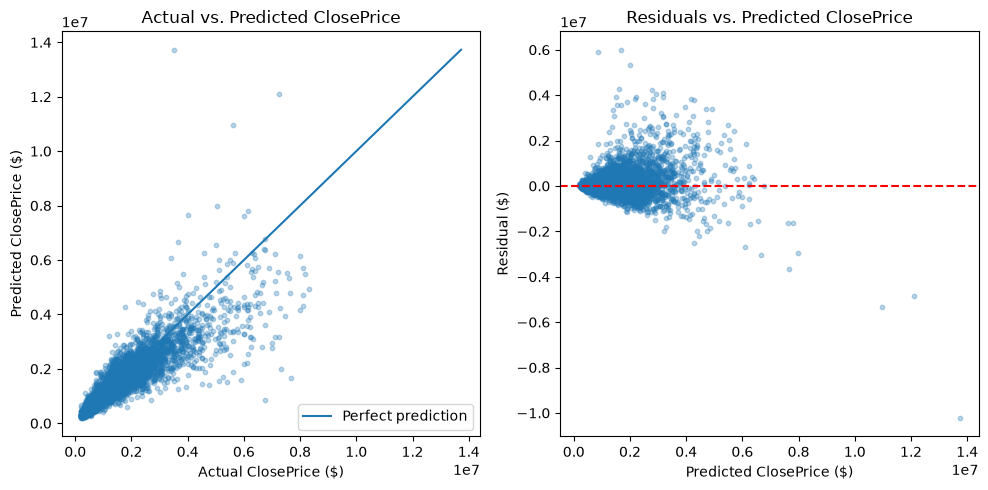

In [58]:
# Visualize validation predictions and residuals
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 1. Actual vs. Predicted ClosePrice
axes[0].scatter(y_val_actual, val_predictions, alpha=0.3, s=10)
price_min = min(y_val_actual.min(), val_predictions.min())
price_max = max(y_val_actual.max(), val_predictions.max())

axes[0].plot([price_min, price_max], [price_min, price_max], label="Perfect prediction")
axes[0].set(title="Actual vs. Predicted ClosePrice", xlabel="Actual ClosePrice ($)", ylabel="Predicted ClosePrice ($)")
axes[0].legend()

# 2. Residuals vs. Predicted ClosePrice
axes[1].scatter(val_predictions, residuals, alpha=0.3, s=10)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(title="Residuals vs. Predicted ClosePrice", xlabel="Predicted ClosePrice ($)", ylabel="Residual ($)")

plt.tight_layout()
plt.show()

Note: The current preprocessing rules and baseline model results
are preliminary and may be updated following team review.
Final test-set evaluation will be performed after the
preprocessing approach is finalized.

## Alternative Baseline Regression Model

In [59]:
# ---------------------------------------------------------------
# Notebook cells: TransformedTargetRegressor + cross_validate
# Paste each "# %%" block into its own cell, after the cell that
# defines `model_pipeline`, `train_sorted`, `model_features`,
# `cv_splits`, `X_val`, and `clean_validation_df`.
# ---------------------------------------------------------------

# %% Imports
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_validate
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# %% Wrap the pipeline so the log transform lives inside the model
# The wrapper applies log1p to y when fitting and expm1 to predictions,
# so predict() returns dollars and sklearn's built-in scorers work as-is.
# IMPORTANT: pass the RAW ClosePrice as y, not LogClosePrice,
# otherwise the target would be log-transformed twice.
ttr_pipeline = TransformedTargetRegressor(
    regressor=model_pipeline,
    func=np.log1p,
    inverse_func=np.expm1,
)

X_cv = train_sorted[model_features].copy()
y_cv_price = train_sorted["ClosePrice"]          # dollars, not log

# %% Month-based expanding-window CV with several metrics at once
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}

cv_out = cross_validate(
    ttr_pipeline, X_cv, y_cv_price,
    cv=cv_splits,               # the same custom monthly splits
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1,
)

cv_table = pd.DataFrame({
    "Validation Month": validation_months,
    "Val R²":   cv_out["test_r2"],
    "Val MAE":  -cv_out["test_mae"],
    "Val RMSE": -cv_out["test_rmse"],
    "Train R²": cv_out["train_r2"],
    "Fit time (s)": cv_out["fit_time"],
})
display(cv_table)
print(f"Mean CV R²:   {cv_table['Val R²'].mean():.4f}")
print(f"Mean CV MAE:  ${cv_table['Val MAE'].mean():,.0f}")
print(f"Mean CV RMSE: ${cv_table['Val RMSE'].mean():,.0f}")

# %% Out-of-fold predictions
# cross_val_predict() cannot be used here: expanding-window splits are not a
# partition (the first months are never validated), so it raises ValueError.
# A manual loop gives the same thing for the validated months.
oof_frames = []
for train_idx, val_idx in cv_splits:
    est = clone(ttr_pipeline).fit(X_cv.iloc[train_idx], y_cv_price.iloc[train_idx])
    oof_frames.append(pd.DataFrame({
        "month": train_sorted.iloc[val_idx]["SourceMonth"].values,
        "actual": y_cv_price.iloc[val_idx].values,
        "predicted": est.predict(X_cv.iloc[val_idx]),
    }, index=X_cv.index[val_idx]))

oof = pd.concat(oof_frames)
oof["residual"] = oof["actual"] - oof["predicted"]
oof["abs_error"] = oof["residual"].abs()

# Error by month, as a quick check on stability over time
display(oof.groupby("month").agg(
    n=("actual", "size"),
    MAE=("abs_error", "mean"),
    median_residual=("residual", "median"),
))

# %% Final fit and March 2026 validation (dollar scale, no manual expm1)
ttr_pipeline.fit(X_train, clean_train_df["ClosePrice"])
val_pred = ttr_pipeline.predict(X_val)
val_actual = clean_validation_df["ClosePrice"]

print(f"Validation R²:   {r2_score(val_actual, val_pred):.4f}")
print(f"Validation MAE:  ${mean_absolute_error(val_actual, val_pred):,.2f}")
print(f"Validation RMSE: ${np.sqrt(mean_squared_error(val_actual, val_pred)):,.2f}")

,Validation Month,Val R²,Val MAE,Val RMSE,Train R²,Fit time (s)
0,2025-10,0.818372,201597.327315,400440.671782,0.828670,1.376418
1,2025-11,0.804613,206815.509482,420094.980561,0.828259,1.720097
2,2025-12,0.808336,198606.388014,399776.170242,0.827381,1.570140
3,2026-01,0.777434,207026.745285,430918.550201,0.826803,1.735662
4,2026-02,0.793776,217233.184223,444426.635016,0.825663,1.964418


Mean CV R²:   0.8005
Mean CV MAE:  $206,256
Mean CV RMSE: $419,131


c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify 

,n,MAE,median_residual
month,,,
2025-10,11847,201597.327315,-6996.255344
2025-11,9590,206815.509482,-8629.606488
2025-12,10292,198606.388014,-10012.394159
2026-01,7358,207026.745285,-12772.116679
2026-02,8839,217233.184223,-2313.468993


c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Validation R²:   0.7962
Validation MAE:  $211,145.26
Validation RMSE: $428,784.46


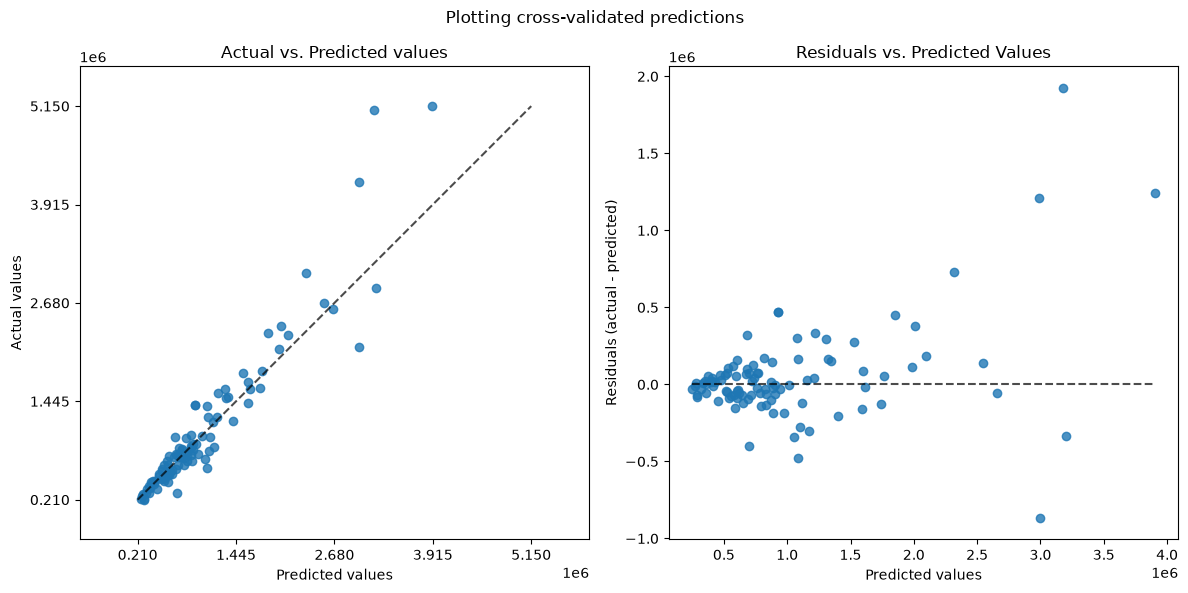

In [60]:
import matplotlib.pyplot as plt

from sklearn.metrics import PredictionErrorDisplay

fig, axs = plt.subplots(ncols=2, figsize=(12, 6))
PredictionErrorDisplay.from_predictions(
    val_actual,
    y_pred=val_pred,
    kind="actual_vs_predicted",
    subsample=100,
    ax=axs[0],
    random_state=0,
)
axs[0].set_title("Actual vs. Predicted values")
PredictionErrorDisplay.from_predictions(
    val_actual,
    y_pred=val_pred,
    kind="residual_vs_predicted",
    subsample=100,
    ax=axs[1],
    random_state=0,
)
axs[1].set_title("Residuals vs. Predicted Values")
fig.suptitle("Plotting cross-validated predictions")
plt.tight_layout()
plt.show()

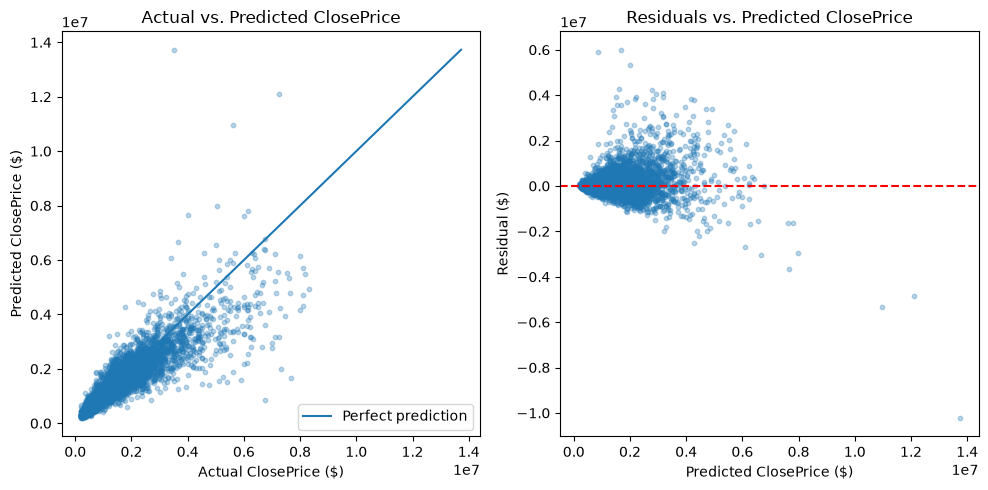

In [61]:
# Visualize validation predictions and residuals
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 1. Actual vs. Predicted ClosePrice
axes[0].scatter(y_val_actual, val_predictions, alpha=0.3, s=10)
price_min = min(y_val_actual.min(), val_predictions.min())
price_max = max(y_val_actual.max(), val_predictions.max())

axes[0].plot([price_min, price_max], [price_min, price_max], label="Perfect prediction")
axes[0].set(title="Actual vs. Predicted ClosePrice", xlabel="Actual ClosePrice ($)", ylabel="Predicted ClosePrice ($)")
axes[0].legend()

# 2. Residuals vs. Predicted ClosePrice
axes[1].scatter(val_predictions, residuals, alpha=0.3, s=10)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(title="Residuals vs. Predicted ClosePrice", xlabel="Predicted ClosePrice ($)", ylabel="Residual ($)")

plt.tight_layout()
plt.show()

## Decision Tree Regression

This section adds a Decision Tree Regressor as a nonlinear comparison to the Linear Regression baseline. It reuses the existing feature set, preprocessing pipeline, chronological expanding-window cross-validation splits, and March 2026 holdout validation set.

The model is trained on `ClosePrice` with a `log1p` target transformation and predictions are converted back to dollars. The tree's depth and minimum leaf size are constrained to reduce overfitting; these are initial settings, not tuned hyperparameters.

In [62]:
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_validate

# Keep preprocessing identical to the linear model; replace only the estimator.
tree_regressor = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=20,
        random_state=42
    ))
])

tree_pipeline = TransformedTargetRegressor(
    regressor=tree_regressor,
    func=np.log1p,
    inverse_func=np.expm1
)

# Cross-validation uses the same chronological splits as the baseline.
tree_cv_out = cross_validate(
    tree_pipeline,
    X_cv,
    y_cv_price,
    cv=cv_splits,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    },
    return_train_score=True,
    n_jobs=-1
)

tree_cv_table = pd.DataFrame({
    "Validation Month": validation_months,
    "Val R²": tree_cv_out["test_r2"],
    "Val MAE": -tree_cv_out["test_mae"],
    "Val RMSE": -tree_cv_out["test_rmse"],
    "Train R²": tree_cv_out["train_r2"]
})
display(tree_cv_table)

print(f"Mean tree CV R²:   {tree_cv_table['Val R²'].mean():.4f}")
print(f"Mean tree CV MAE:  ${tree_cv_table['Val MAE'].mean():,.0f}")
print(f"Mean tree CV RMSE: ${tree_cv_table['Val RMSE'].mean():,.0f}")

,Validation Month,Val R²,Val MAE,Val RMSE,Train R²
0,2025-10,0.854830,184283.316308,358002.026841,0.878995
1,2025-11,0.840667,185846.520675,379360.972986,0.878660
2,2025-12,0.842191,179551.604726,362754.254176,0.878461
3,2026-01,0.852644,180108.794801,350630.180786,0.878997
4,2026-02,0.853925,188414.729849,374040.855114,0.877673


Mean tree CV R²:   0.8489
Mean tree CV MAE:  $183,641
Mean tree CV RMSE: $364,958


In [63]:
# Fit on the selected training window and evaluate on the held-out validation set.
tree_pipeline.fit(X_train, clean_train_df["ClosePrice"])
tree_val_pred = tree_pipeline.predict(X_val)
tree_val_actual = clean_validation_df["ClosePrice"]

tree_val_r2 = r2_score(tree_val_actual, tree_val_pred)
tree_val_mae = mean_absolute_error(tree_val_actual, tree_val_pred)
tree_val_rmse = np.sqrt(mean_squared_error(tree_val_actual, tree_val_pred))

print(f"Decision Tree validation R²:   {tree_val_r2:.4f}")
print(f"Decision Tree validation MAE:  ${tree_val_mae:,.2f}")
print(f"Decision Tree validation RMSE: ${tree_val_rmse:,.2f}")

c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Decision Tree validation R²:   0.8534
Decision Tree validation MAE:  $186,043.56
Decision Tree validation RMSE: $363,678.60


In [ ]:
#pip install Jinja2 --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [65]:
from pandas.io.formats.style import Styler

In [66]:
# Compare models using matching evaluation windows and metrics.
# Linear CV metrics come from the existing TransformedTargetRegressor CV section.
model_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Mean CV R²": cv_table["Val R²"].mean(),
        "Mean CV MAE": cv_table["Val MAE"].mean(),
        "Mean CV RMSE": cv_table["Val RMSE"].mean(),
        "March 2026 Validation R²": r2_score(clean_validation_df["ClosePrice"], val_pred),
        "March 2026 Validation MAE": mean_absolute_error(clean_validation_df["ClosePrice"], val_pred),
        "March 2026 Validation RMSE": np.sqrt(mean_squared_error(clean_validation_df["ClosePrice"], val_pred))
    },
    {
        "Model": "Decision Tree (depth=12, leaf=20)",
        "Mean CV R²": tree_cv_table["Val R²"].mean(),
        "Mean CV MAE": tree_cv_table["Val MAE"].mean(),
        "Mean CV RMSE": tree_cv_table["Val RMSE"].mean(),
        "March 2026 Validation R²": tree_val_r2,
        "March 2026 Validation MAE": tree_val_mae,
        "March 2026 Validation RMSE": tree_val_rmse
    }
])

display(model_comparison.style.format({
    "Mean CV R²": "{:.4f}",
    "Mean CV MAE": "${:,.0f}",
    "Mean CV RMSE": "${:,.0f}",
    "March 2026 Validation R²": "{:.4f}",
    "March 2026 Validation MAE": "${:,.0f}",
    "March 2026 Validation RMSE": "${:,.0f}"
}))

,Model,Mean CV R²,Mean CV MAE,Mean CV RMSE,March 2026 Validation R²,March 2026 Validation MAE,March 2026 Validation RMSE
0,Linear Regression,0.8005,"$206,256","$419,131",0.7962,"$211,145","$428,784"
1,"Decision Tree (depth=12, leaf=20)",0.8489,"$183,641","$364,958",0.8534,"$186,044","$363,679"


### Interpreting the comparison

- **R²:** Higher is better.
- **MAE and RMSE:** Lower is better; RMSE penalizes large errors more heavily.
- Use the chronological cross-validation results to compare performance across recent training months, and the March 2026 validation results as a separate held-out check.
- A large gap between training and validation R² can indicate overfitting. Decision trees can be sensitive to `max_depth` and `min_samples_leaf`; consider tuning these values using only the chronological training folds before selecting a final model.
- The tree and linear model use the same input features and preprocessing, but the tree does not require feature standardization. Keeping the shared preprocessing makes this first comparison easier to interpret, though a later tree-specific preprocessing pipeline could simplify it.

Text(0.5, 1.0, 'Decision Tree Validation Results')

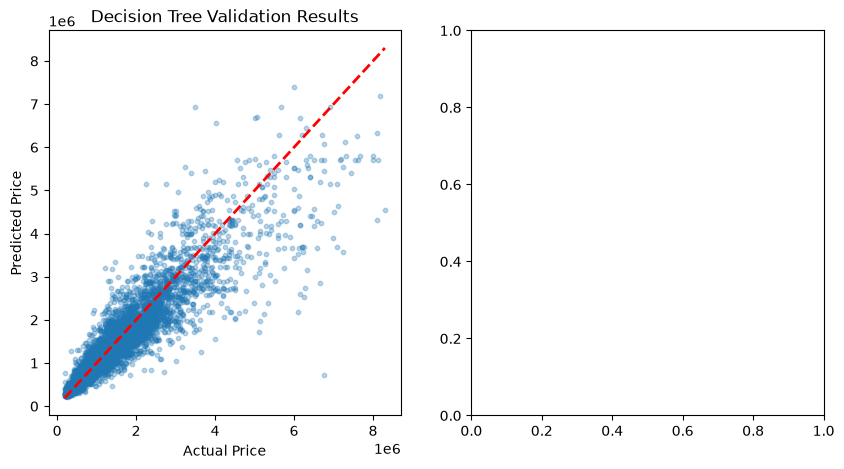

In [ ]:
# Visualize Decision Tree validation predictions and residuals
import matplotlib.pyplot as plt

plt.figure()
plt.scatter(X_train, y, s=20, edgecolor="black", c="darkorange", label="data")
plt.plot(tree_train, tree_pred, color="cornflowerblue", label="max_depth=12", linewidth=2)
plt.plot(tree_val_pred, tree_val_actual, color="lightgreen", label="max_depth=12", linewidth=2)
plt.xlabel("data")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.legend()
plt.show()


------------------------------------------------------------------------------------------------------------------------------------------------

## Alternative Decision Tree Models
### Ensemble Methods

* **Boosted trees:** Incrementally building an ensemble by training each new instance to emphasize the training instances previously mis-modeled. A typical example is AdaBoost. These can be used for regression-type and classification-type problems.
* **Committees of decision trees** (also called k-DT): an early method that used randomized decision tree algorithms to generate multiple different trees from the training data, and then combine them using majority voting to generate output.
* **Bootstrap aggregated (or bagged) decision trees:** an early ensemble method, builds multiple decision trees by repeatedly resampling training data with replacement, and voting the trees for a consensus prediction.
*A random forest classifier is a specific type of bootstrap aggregating
* **Rotation forest:** in which every decision tree is trained by first applying principal component analysis (PCA) on a random subset of the input features.

## AdaBoosted Decision Model

In [ ]:
from sklearn.ensemble import AdaBoostRegressor

regr_2 = AdaBoostRegressor(
    DecisionTreeRegressor(max_depth=4), n_estimators=300, random_state=rng
)

regr_2.fit(X, y)

y_2 = regr_2.predict(X)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

colors = sns.color_palette("colorblind")

plt.figure()
plt.scatter(X, y, color=colors[0], label="training samples")
plt.plot(X, y_2, color=colors[2], label="n_estimators=300", linewidth=2)
plt.xlabel("data")
plt.ylabel("target")
plt.title("Boosted Decision Tree Regression")
plt.legend()
plt.show()

## Random Forest Classifier?

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=80_000, random_state=10)

X_full_train, X_test, y_full_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=10
)
X_train_ensemble, X_train_linear, y_train_ensemble, y_train_linear = train_test_split(
    X_full_train, y_full_train, test_size=0.5, random_state=10
)

In [ ]:
n_estimators = 10
max_depth = 3

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=n_estimators, max_depth=max_depth, random_state=10
)
random_forest.fit(X_train_ensemble, y_train_ensemble)

gradient_boosting = GradientBoostingClassifier(
    n_estimators=n_estimators, max_depth=max_depth, random_state=10
)
_ = gradient_boosting.fit(X_train_ensemble, y_train_ensemble)

In [ ]:
from sklearn.ensemble import RandomTreesEmbedding

random_tree_embedding = RandomTreesEmbedding(
    n_estimators=n_estimators, max_depth=max_depth, random_state=0
)
#random_tree_embedding.fit(X_train_ensemble, y_train_ensemble)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

rt_model = make_pipeline(random_tree_embedding, LogisticRegression(max_iter=1000))
rt_model.fit(X_train_linear, y_train_linear)

In [ ]:
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder


def rf_apply(X, model):
    return model.apply(X)


rf_leaves_yielder = FunctionTransformer(rf_apply, kw_args={"model": random_forest})

rf_model = make_pipeline(
    rf_leaves_yielder,
    OneHotEncoder(handle_unknown="ignore"),
    LogisticRegression(max_iter=1000),
)
rf_model.fit(X_train_linear, y_train_linear)

In [ ]:
def gbdt_apply(X, model):
    return model.apply(X)[:, :, 0]


gbdt_leaves_yielder = FunctionTransformer(
    gbdt_apply, kw_args={"model": gradient_boosting}
)

gbdt_model = make_pipeline(
    gbdt_leaves_yielder,
    OneHotEncoder(handle_unknown="ignore"),
    LogisticRegression(max_iter=1000),
)
gbdt_model.fit(X_train_linear, y_train_linear)

In [ ]:
import matplotlib.pyplot as plt

from sklearn.metrics import RocCurveDisplay

_, ax = plt.subplots()

models = [
    ("RT embedding -> LR", rt_model),
    ("RF", random_forest),
    ("RF embedding -> LR", rf_model),
    ("GBDT", gradient_boosting),
    ("GBDT embedding -> LR", gbdt_model),
]

model_displays = {}
for name, pipeline in models:
    model_displays[name] = RocCurveDisplay.from_estimator(
        pipeline, X_test, y_test, ax=ax, name=name
    )
_ = ax.set_title("ROC curve")

In [ ]:
_, ax = plt.subplots()
for name, pipeline in models:
    model_displays[name].plot(ax=ax)

ax.set_xlim(0, 0.2)
ax.set_ylim(0.8, 1)
_ = ax.set_title("ROC curve (zoomed in at top left)")

## Rotation Forest